# Ejemplo de uso 3: Elección de distintas configuraciones

Este notebook ilustra cómo probar distintas configuraciones a la hora de entrenar un modelo y de generar imágenes. Este archivo se considera una continuación del notebook "Ejemplo de uso 1: Entrenamiento y Generación de un modelo".

En primer lugar, importamos todas las funciones que vamos a necesitar.

In [2]:
from diffusion_functions import train_model, generate_and_plot
from evaluate_metrics import cargar_modelo

Recordamos las posibles opciones que están implementadas en este paquete y que, por tanto, se pueden utilizar, para cada parámetro son:
- n_epochs: un valor entero positivo. se recomienda que se encuentre entre 30 y 50.
- dataset: "mnist" o "cifar10". Por defecto, si no se especifica, así como si se introduce una cadena distinta, se usará CIFAR-10.
- diffusion_type: "ve" (Variance Exploding), "vp" (Variance Preserving), "subvp" (Sub-variance Preserving).
- schedule_type: "exponential", "linear", "cosine".
- sampler: "euler" (Euler-Maruyama), "pc" (Predictor corrector), "pf" (Probability Flow ODE), "expint" (Exponential Integrator).
- label: un valor entero entre 0 y 9
- imputation: True o False.

Como primer ejemplo, vamos a probar a generar imágenes usando el dataset MNIST, el proceso de difusión Variance Preserving y Euler Maruyama como sampler, sin imputación. Mantenemos como en el "Ejemplo de uso 1" el resto de parámetros.

In [4]:
# Configuración del modelo y de la generación
n_epochs = 30
diffusion_type = "vp"
dataset = "mnist"
schedule_type = "exponential"
sampler="euler"
label=3
imputation=False

### Paso 1: Entrenamiento del modelo

In [3]:
model = train_model(n_epochs=n_epochs, dataset=dataset, diffusion_type=diffusion_type, schedule_type = schedule_type)

  3%|▎         | 1/30 [00:44<21:20, 44.17s/it]

Epoch 1/30 - Loss: 326.242538 - BPD: 0.000043


  7%|▋         | 2/30 [01:27<20:28, 43.87s/it]

Epoch 2/30 - Loss: 70.877089 - BPD: 0.000020


 10%|█         | 3/30 [02:13<20:06, 44.68s/it]

...

Epoch 28/30 - Loss: 25.790318 - BPD: 0.000011


 97%|█████████▋| 29/30 [19:09<00:45, 45.54s/it]

Epoch 29/30 - Loss: 25.682944 - BPD: 0.000007


100%|██████████| 30/30 [19:56<00:00, 39.89s/it]

Epoch 30/30 - Loss: 25.623213 - BPD: 0.000009


### Paso 2: Generación de imágenes

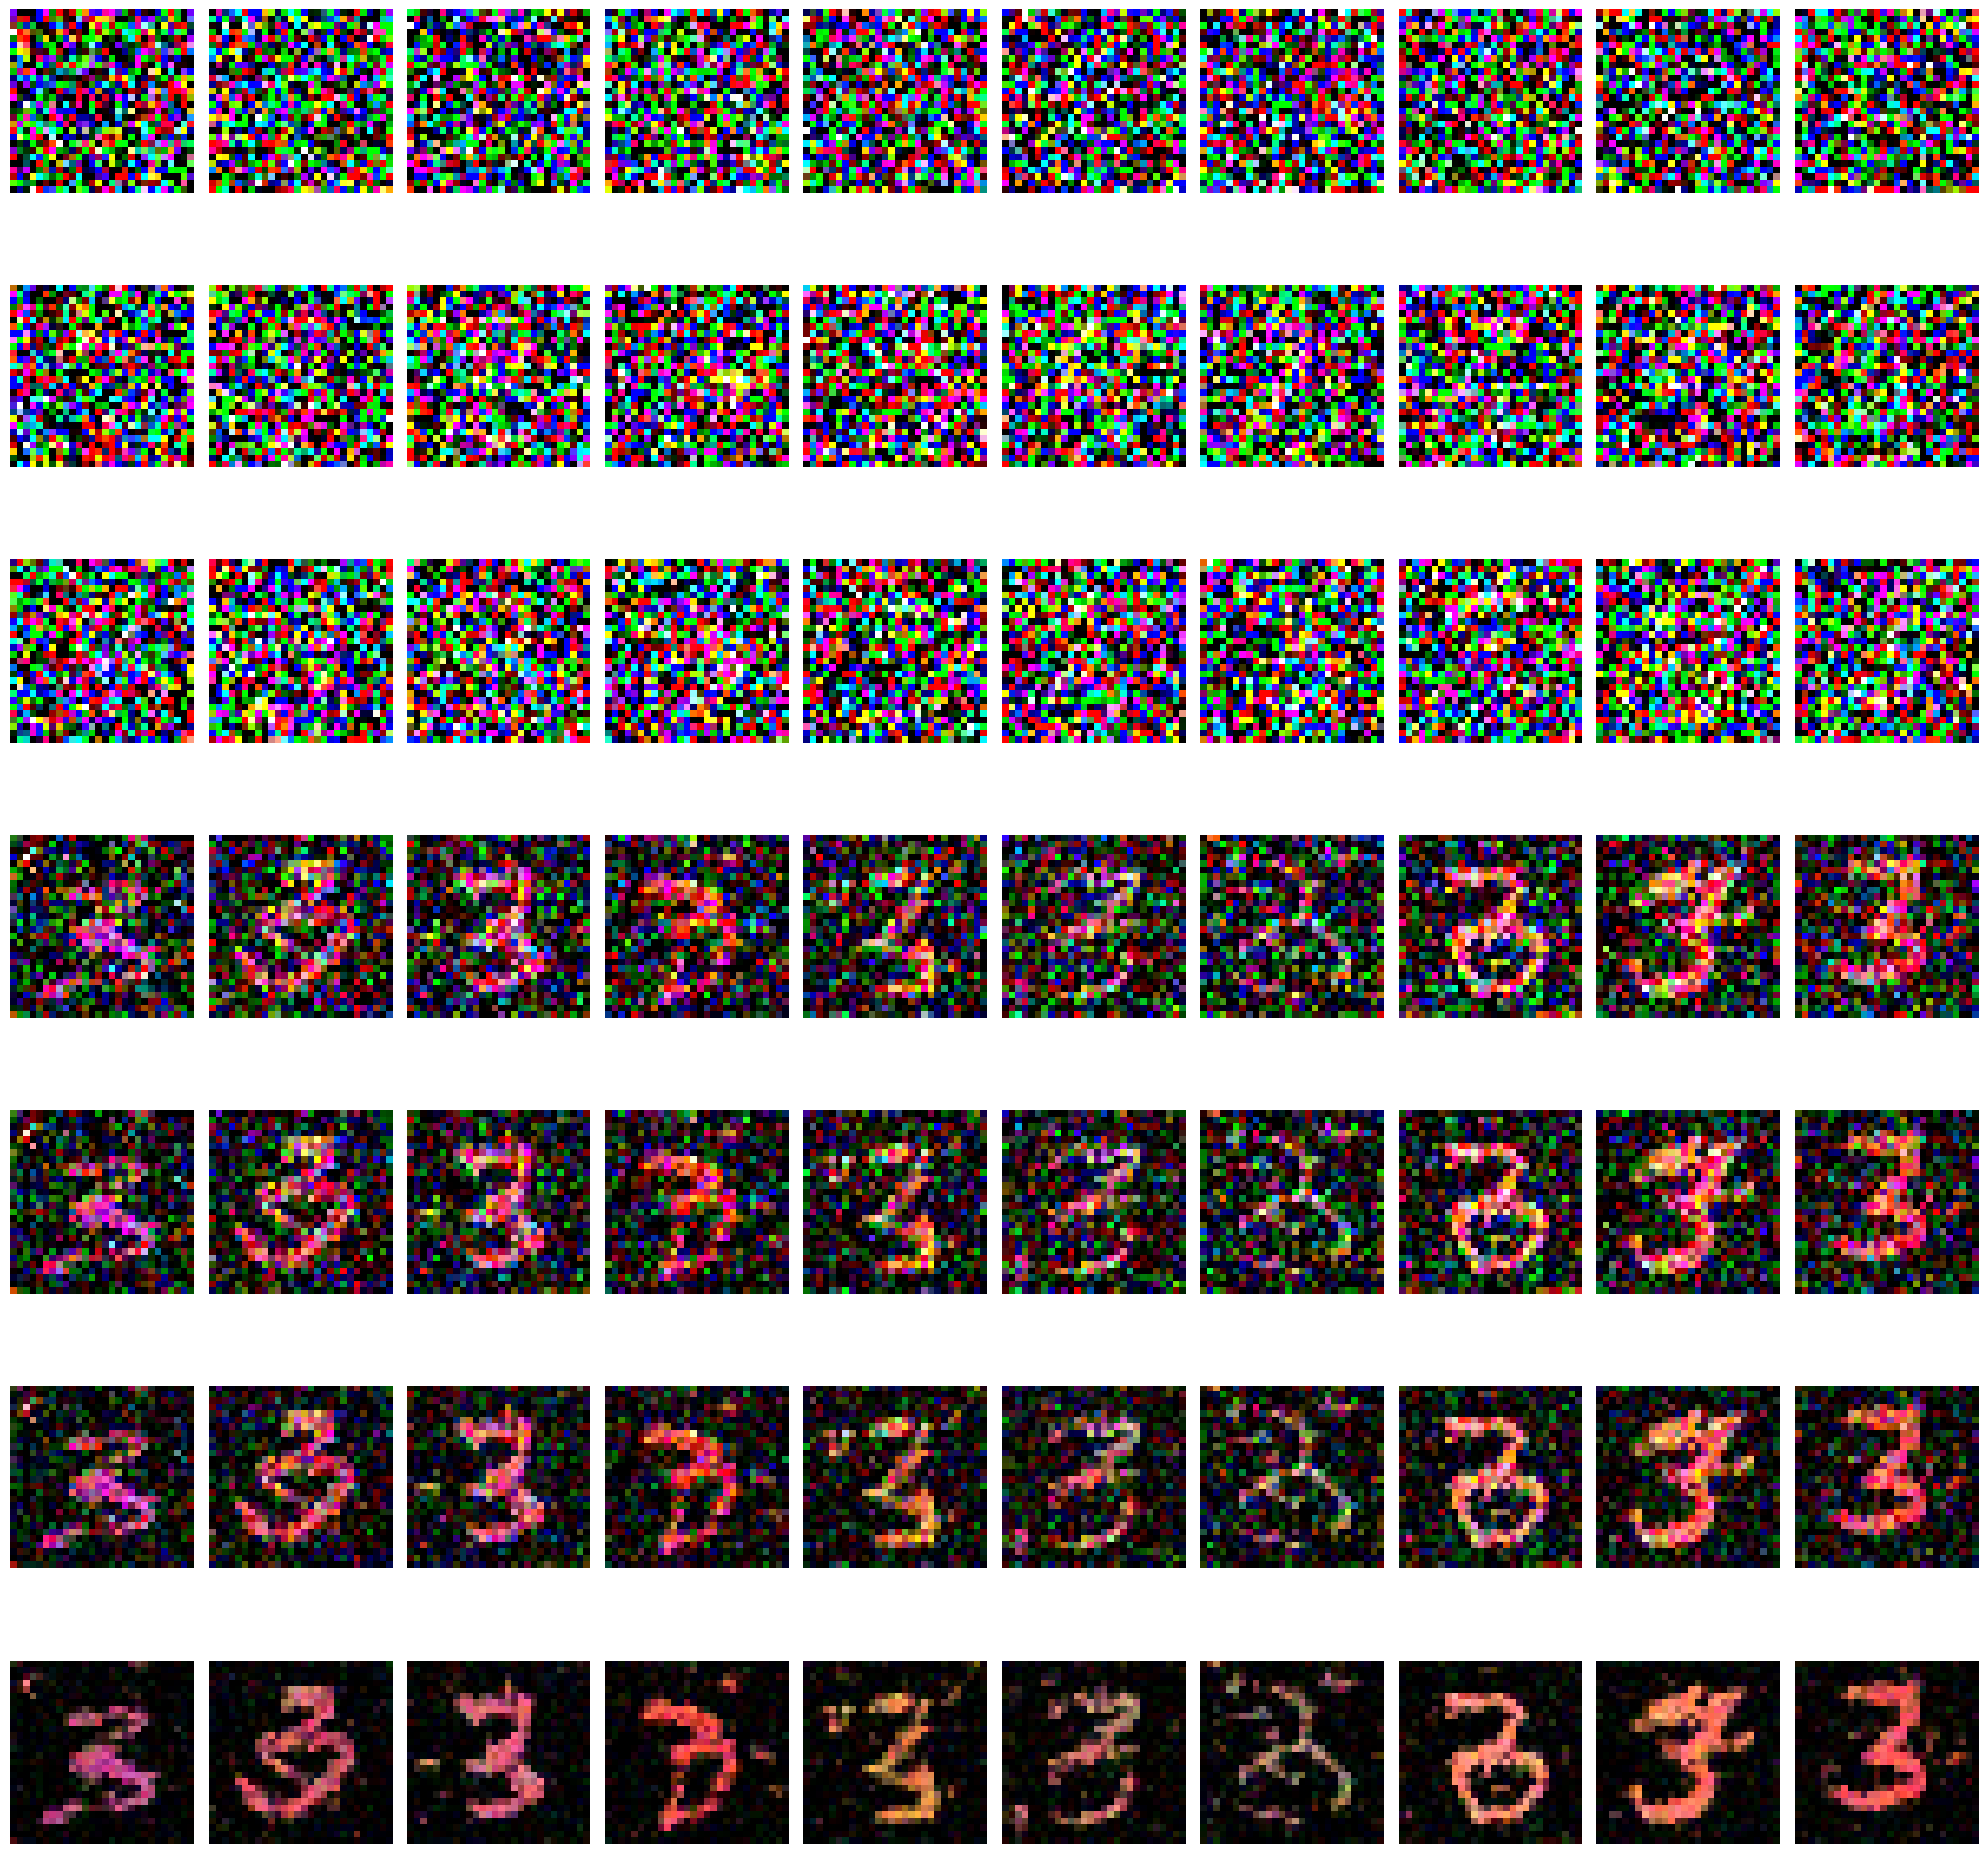

In [7]:
generate_and_plot(model, dataset=dataset, diffusion_type=diffusion_type, schedule_type=schedule_type, sampler=sampler, label=label, imputation=imputation)

In [17]:
train_model(n_epochs=n_epochs, dataset=dataset, diffusion_type='ve', schedule_type = 'exponential')



  3%|▎         | 1/30 [00:38<18:36, 38.50s/it]

Epoch 1/30 - Loss: 387.873833 - BPD: 0.000021


  7%|▋         | 2/30 [01:16<17:45, 38.04s/it]

Epoch 2/30 - Loss: 51.547284 - BPD: 0.000020


 10%|█         | 3/30 [01:54<17:14, 38.33s/it]

...

 97%|█████████▋| 29/30 [20:02<00:40, 40.62s/it]

Epoch 29/30 - Loss: 15.236250 - BPD: 0.000005


100%|██████████| 30/30 [20:42<00:00, 41.40s/it]

Epoch 30/30 - Loss: 14.962369 - BPD: 0.000005


DataParallel(
  (module): ScoreNet(
    (class_embedding): Embedding(10, 256)
    (embed): Sequential(
      (0): GaussianRandomFourierFeatures()
      (1): Linear(in_features=256, out_features=256, bias=True)
    )
    (conv1): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (dense1): Dense(
      (net): Sequential(
        (0): Linear(in_features=256, out_features=128, bias=True)
        (1): SiLU()
        (2): Linear(in_features=128, out_features=128, bias=True)
      )
    )
    (gnorm1): GroupNorm(8, 128, eps=1e-05, affine=True)
    (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (dense2): Dense(
      (net): Sequential(
        (0): Linear(in_features=256, out_features=128, bias=True)
        (1): SiLU()
        (2): Linear(in_features=128, out_features=128, bias=True)
      )
    )
    (gnorm2): GroupNorm(8, 128, eps=1e-05, affine=True)
    (conv3): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2),

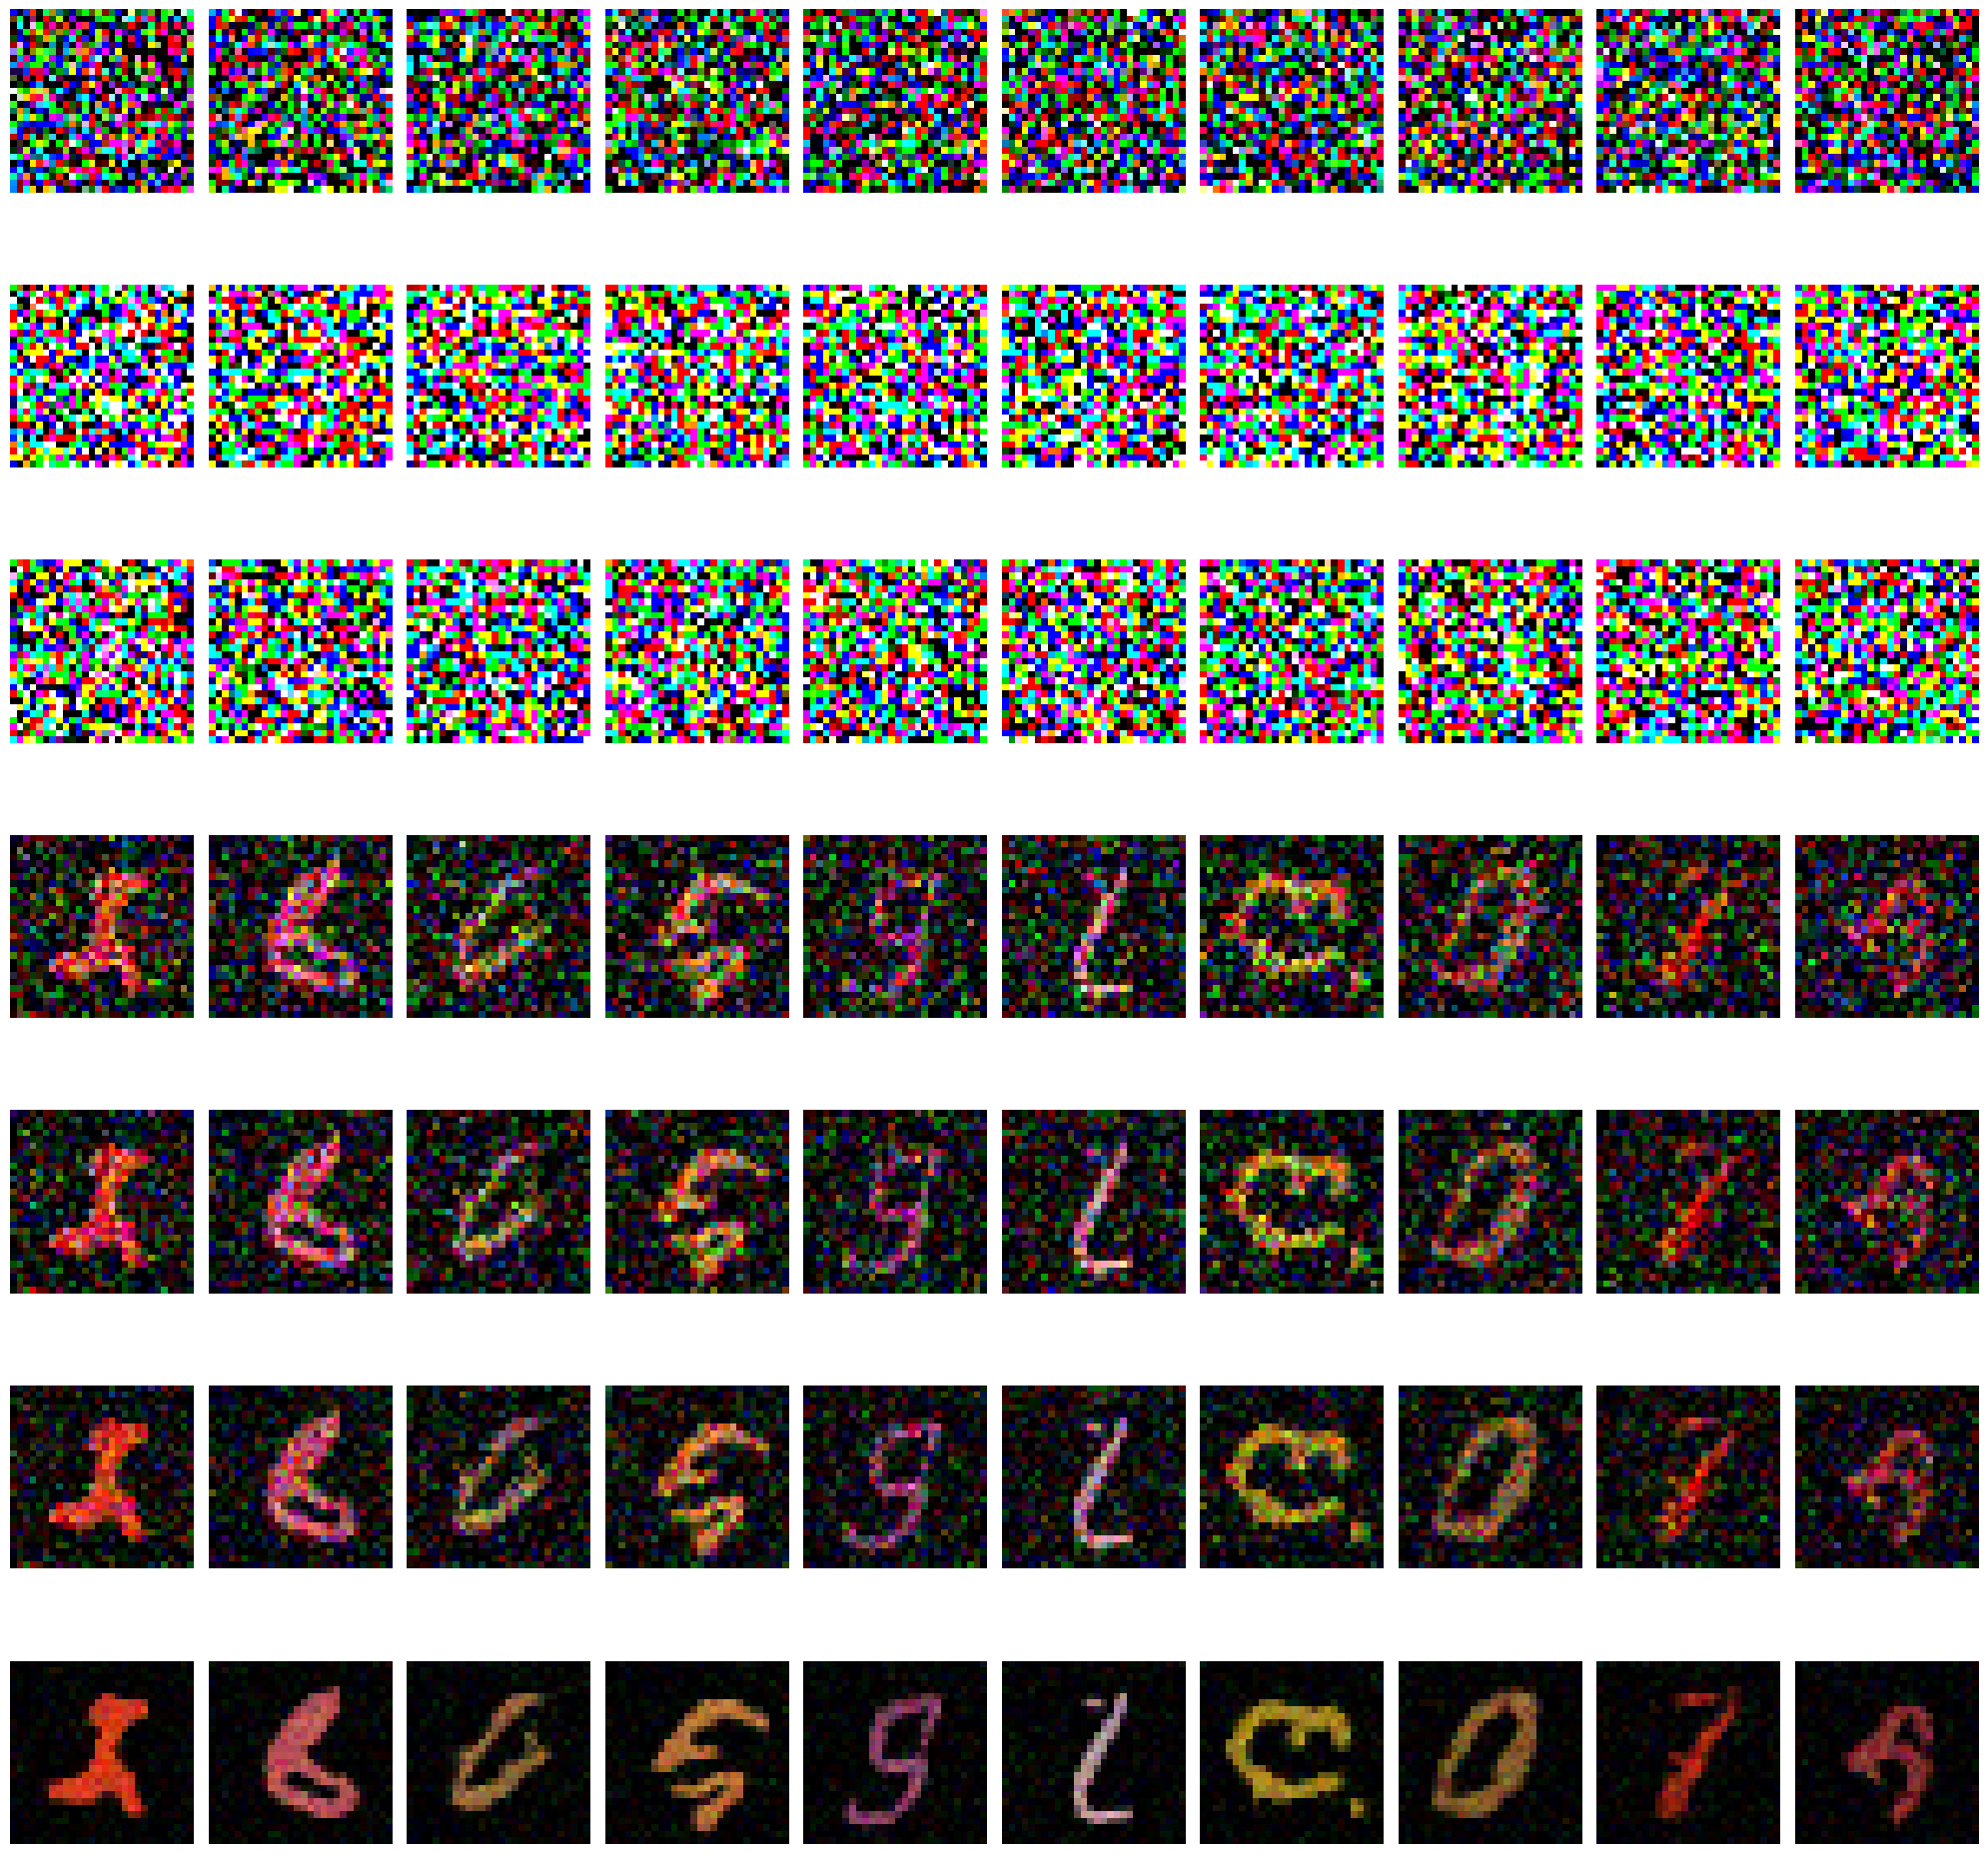

In [16]:
checkpoint_path = "./checkpoints/checkpoint_mnist_ve_exponential.pth"
model = cargar_modelo(checkpoint_path, schedule_type="exponential", diffusion_type="ve")
generate_and_plot(model, dataset=dataset, diffusion_type='ve', schedule_type='exponential', sampler='euler', label=None, imputation=False)

## Etiquetas aleatorias con imputación

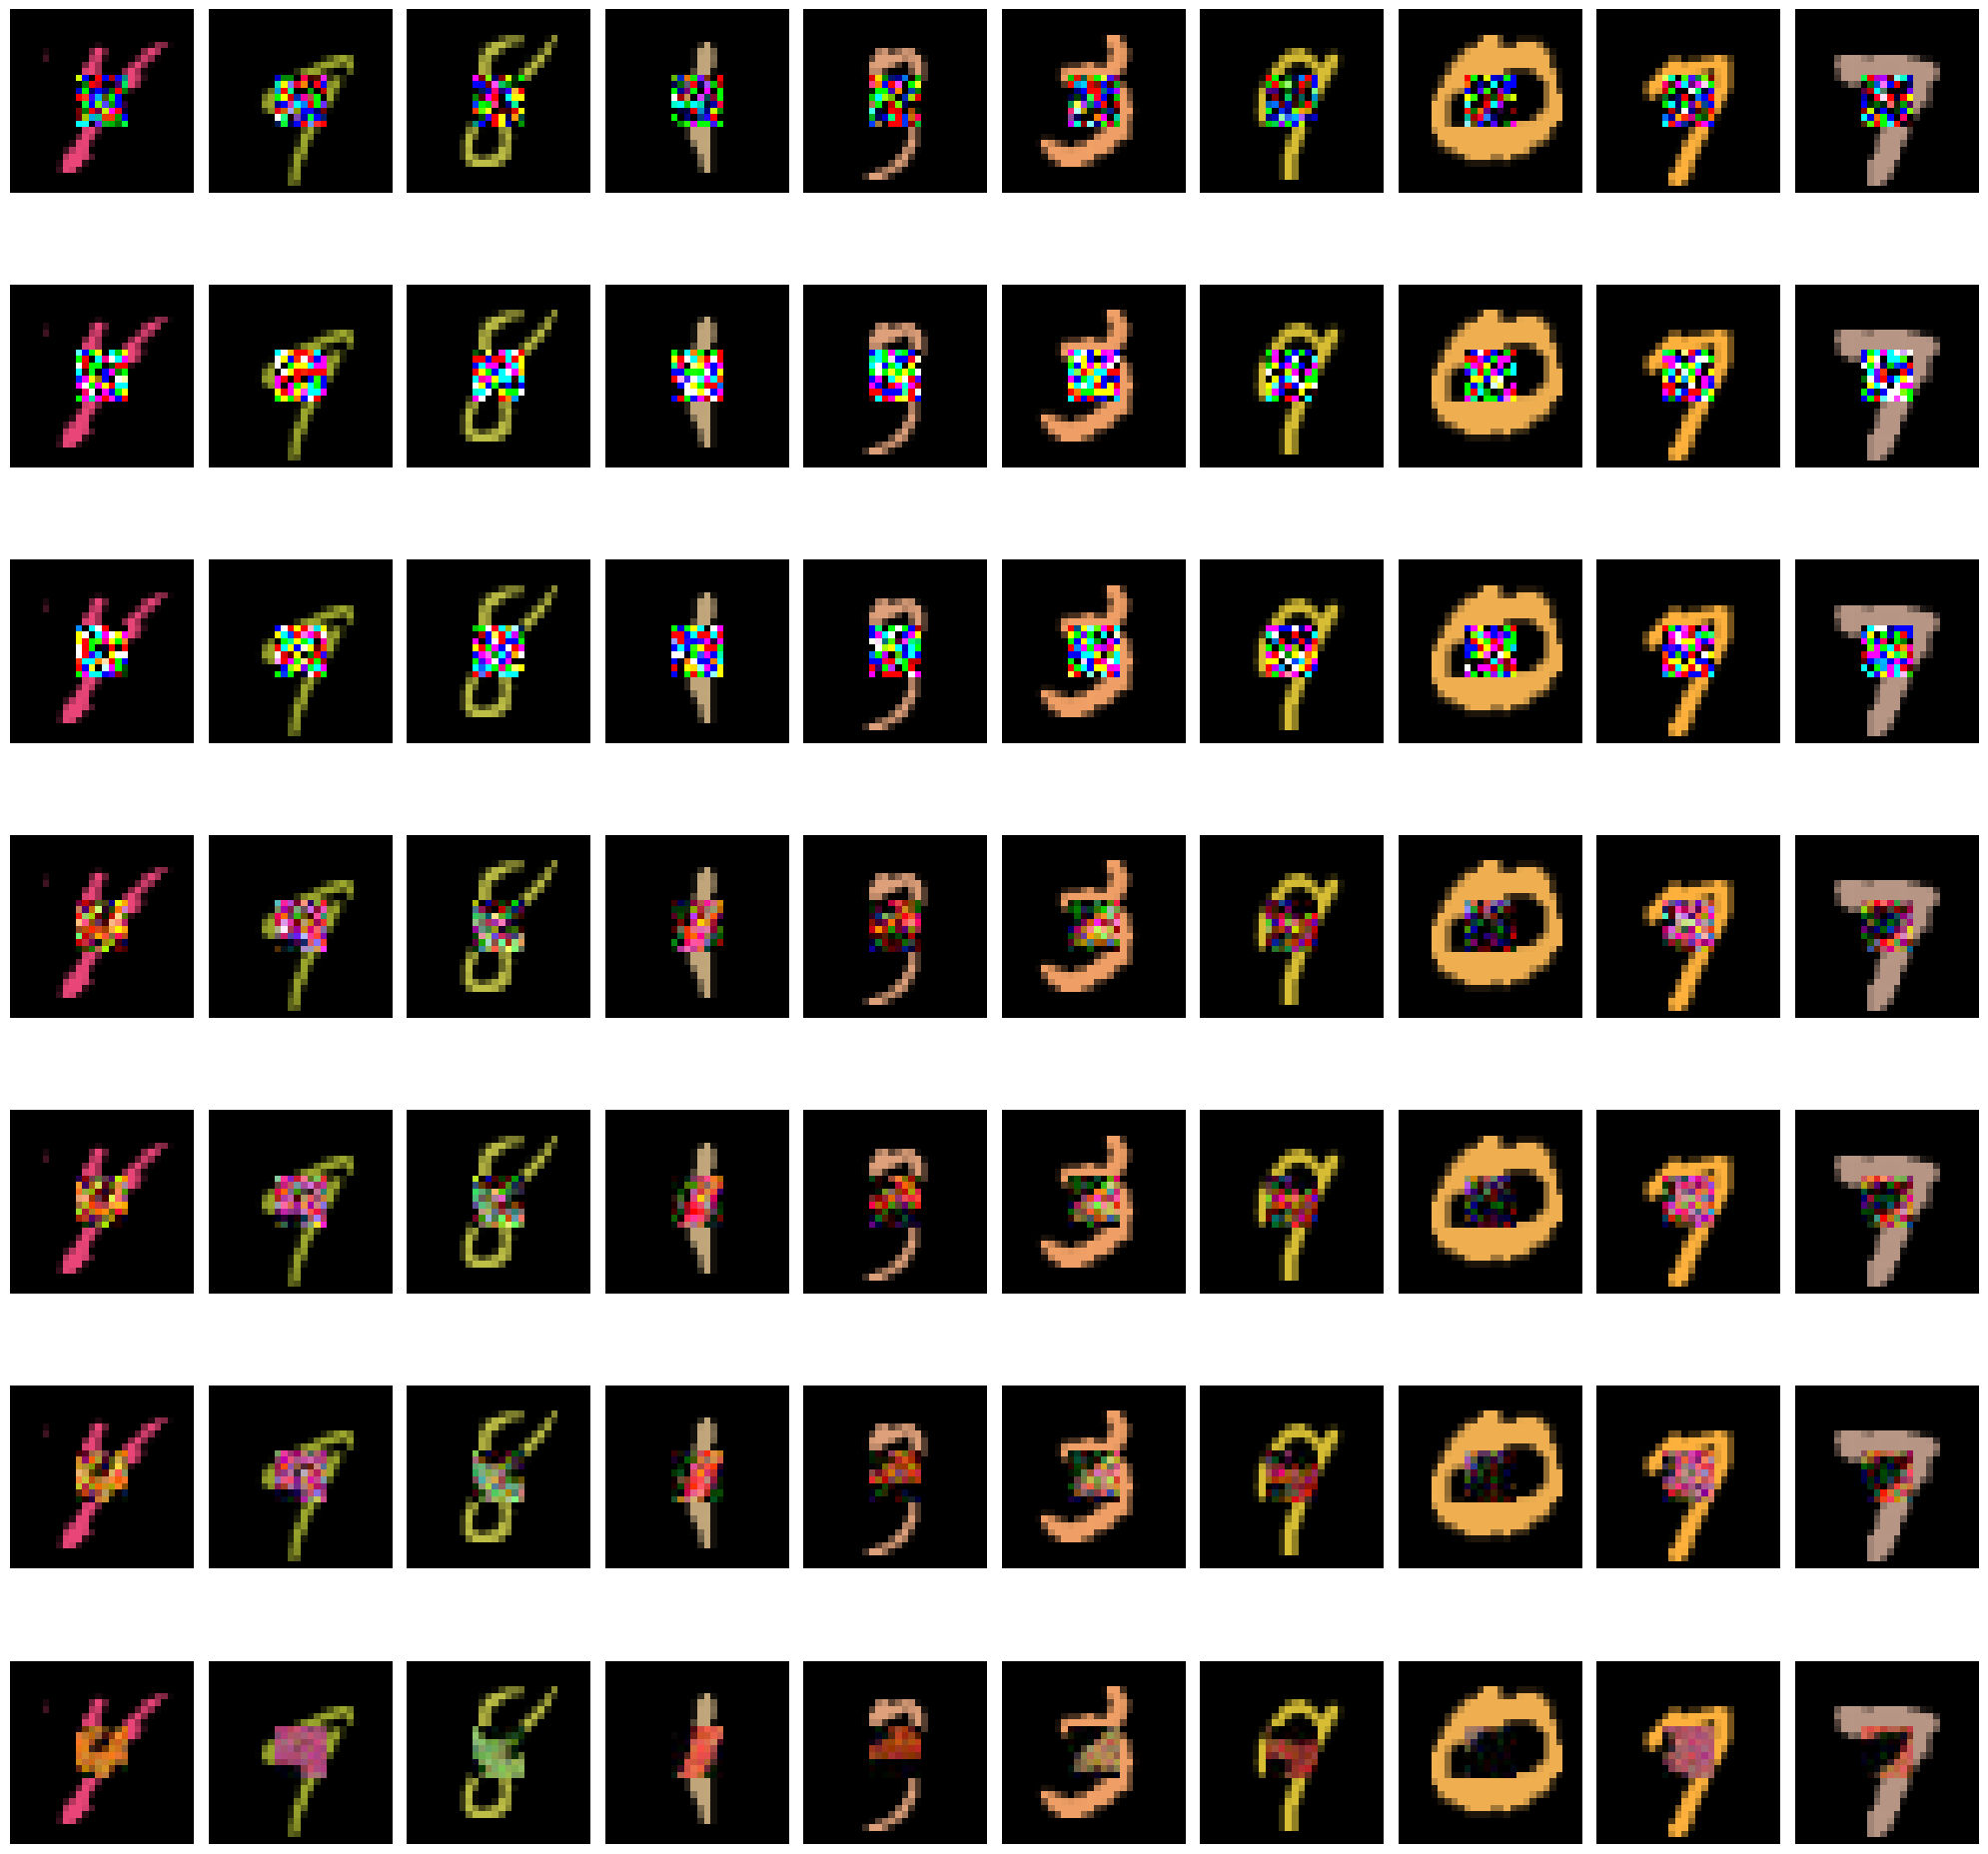

In [20]:
generate_and_plot(model, dataset=dataset, diffusion_type='ve', schedule_type='exponential', sampler='euler', label=None, imputation=True)

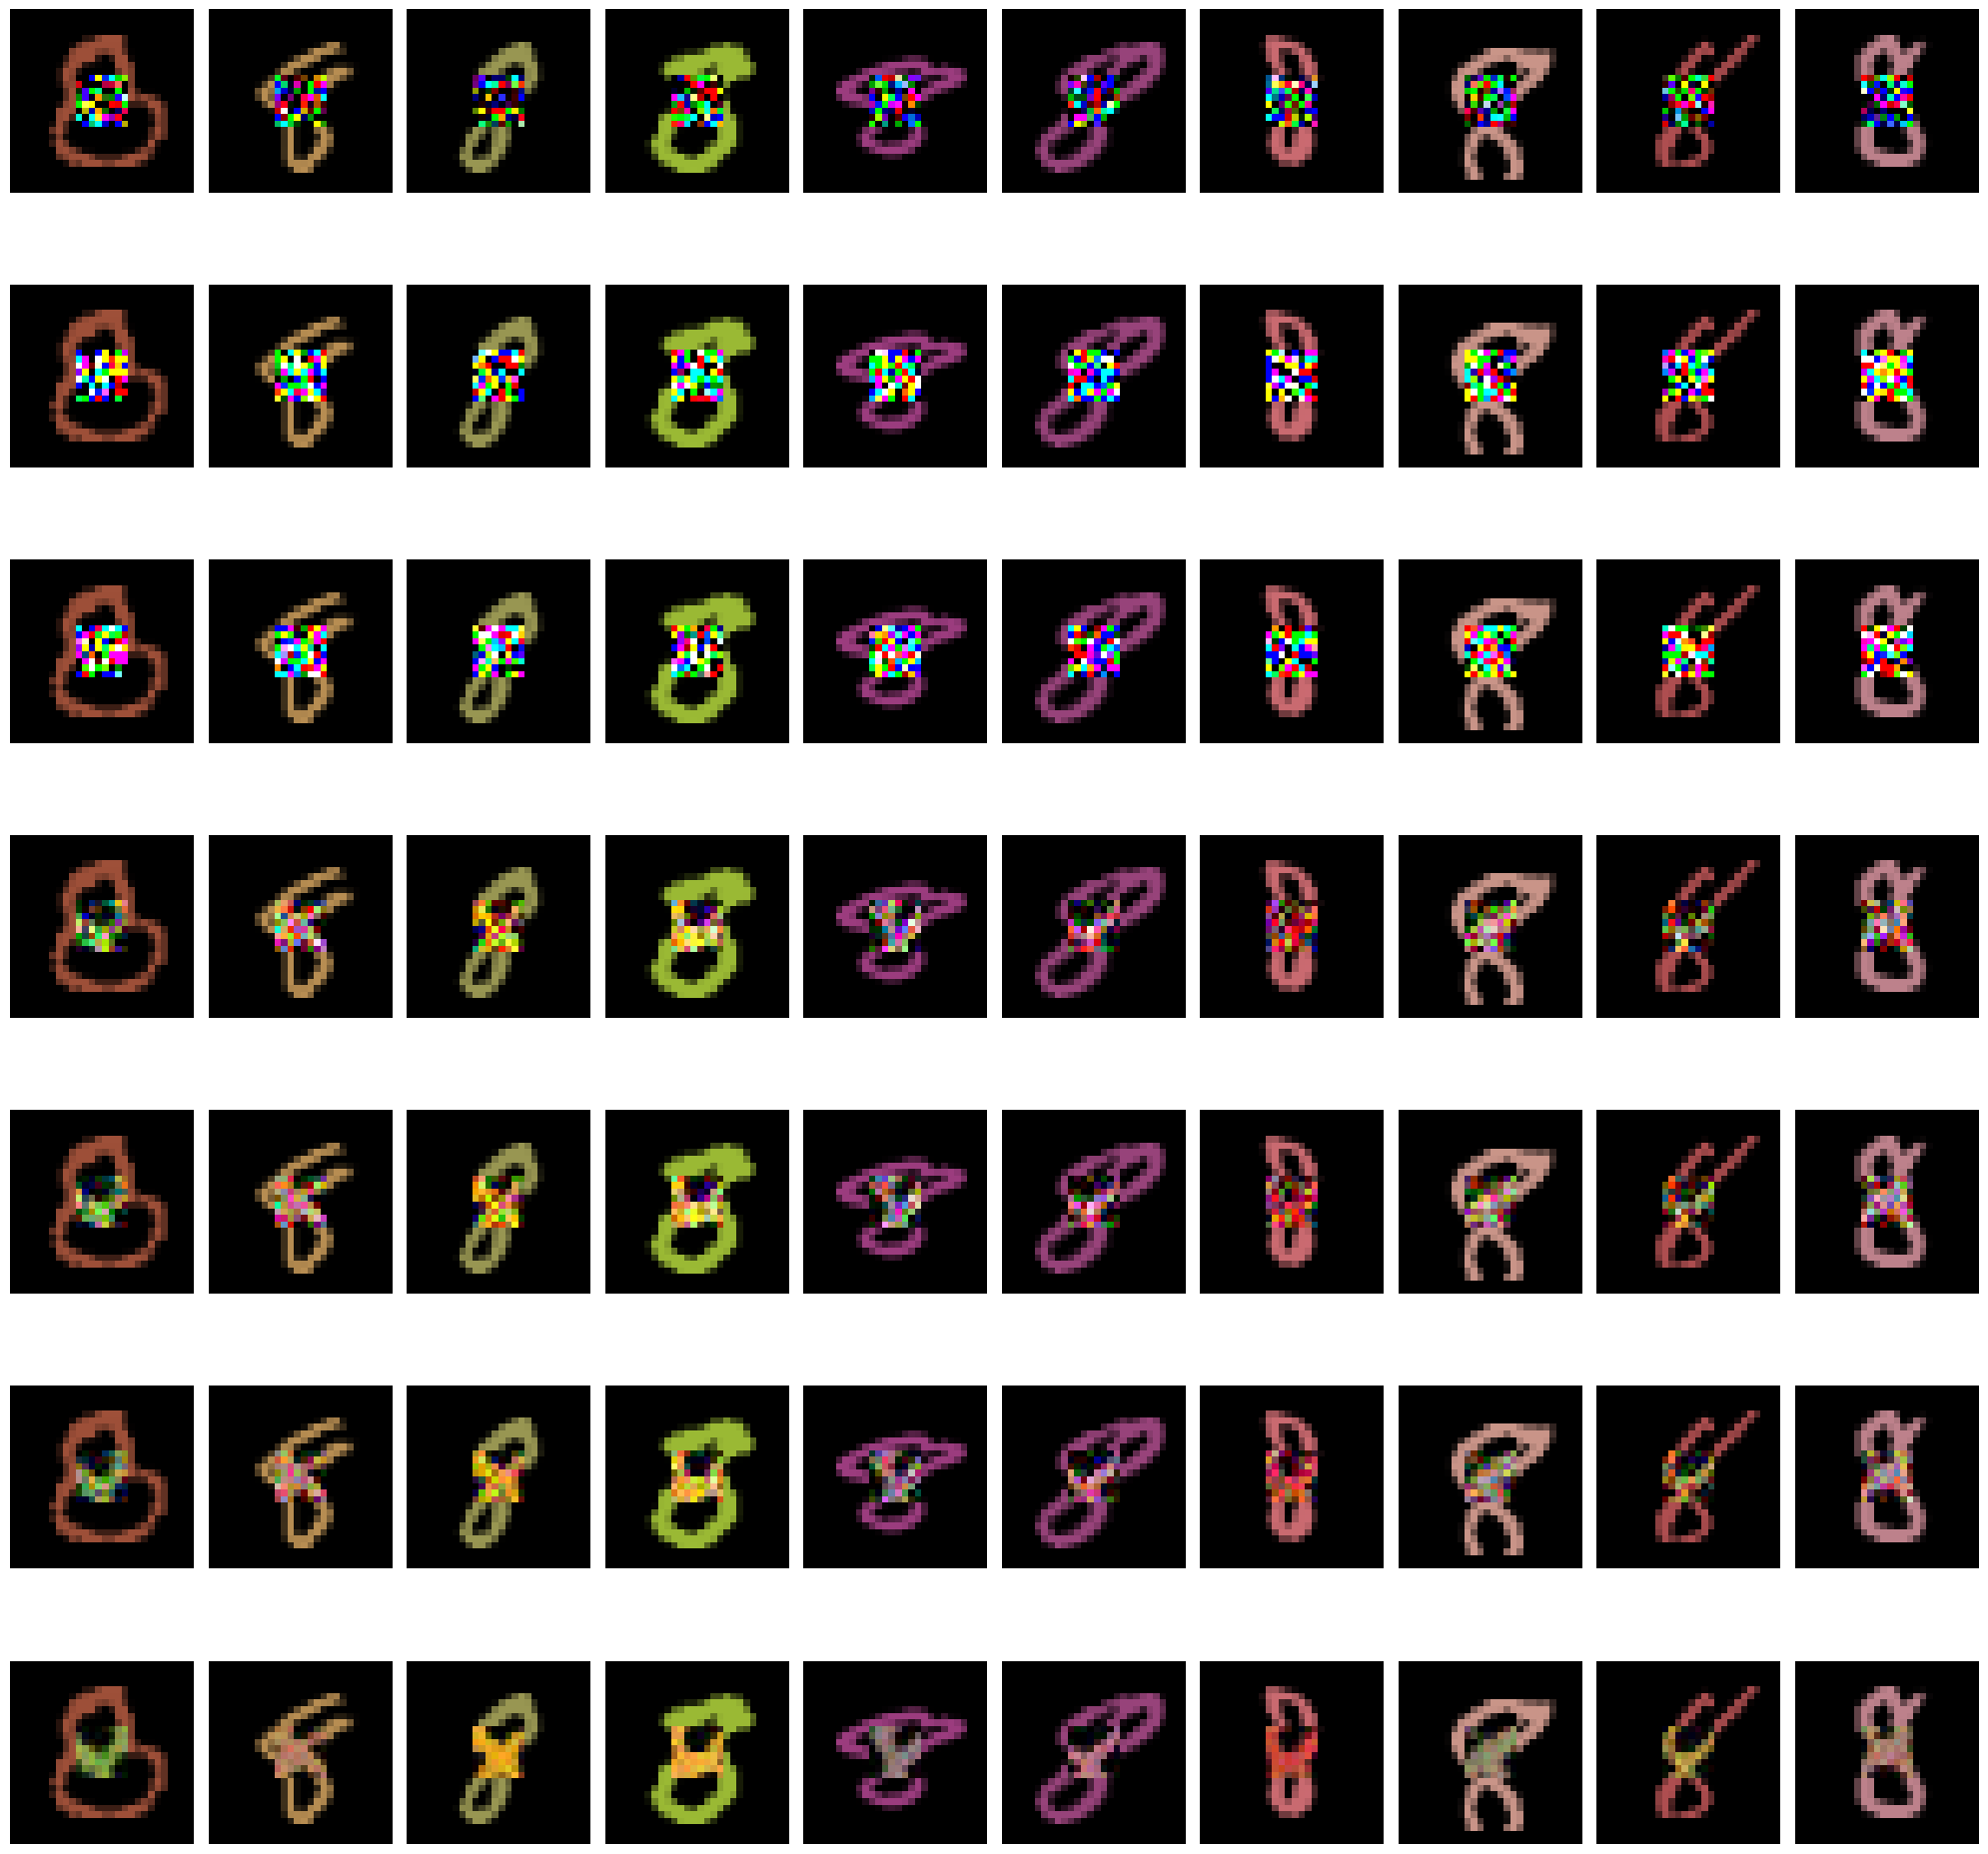

In [24]:
generate_and_plot(model, dataset=dataset, diffusion_type='ve', schedule_type='exponential', sampler='euler', label=8, imputation=True)

## Cambio de dataset y de scheduler. Adición de imputación
En esta sección se ilustra cómo cambiar de scheduler, cambiar al dataset CIFAR-10 y cambiar el parámetro de imputación a True. Al cambiar el dataset y el scheduler, necesitamos volver a entrenar el modelo.

In [8]:
dataset = "cifar10"
imputation = True
schedule_type = "linear"

In [9]:
model_cifar = train_model(n_epochs=n_epochs, dataset=dataset, diffusion_type=diffusion_type, schedule_type = schedule_type)

Files already downloaded and verified


  3%|▎         | 1/30 [00:49<23:45, 49.16s/it]

Epoch 1/30 - Loss: 716.200480 - BPD: 0.000079


  7%|▋         | 2/30 [01:38<22:53, 49.07s/it]

Epoch 2/30 - Loss: 259.359435 - BPD: 0.000084


...

Epoch 28/30 - Loss: 171.753983 - BPD: 0.000016


 97%|█████████▋| 29/30 [13:44<00:24, 24.10s/it]

Epoch 29/30 - Loss: 171.405360 - BPD: 0.000020


100%|██████████| 30/30 [14:08<00:00, 28.28s/it]

Epoch 30/30 - Loss: 171.496127 - BPD: 0.000024


Files already downloaded and verified


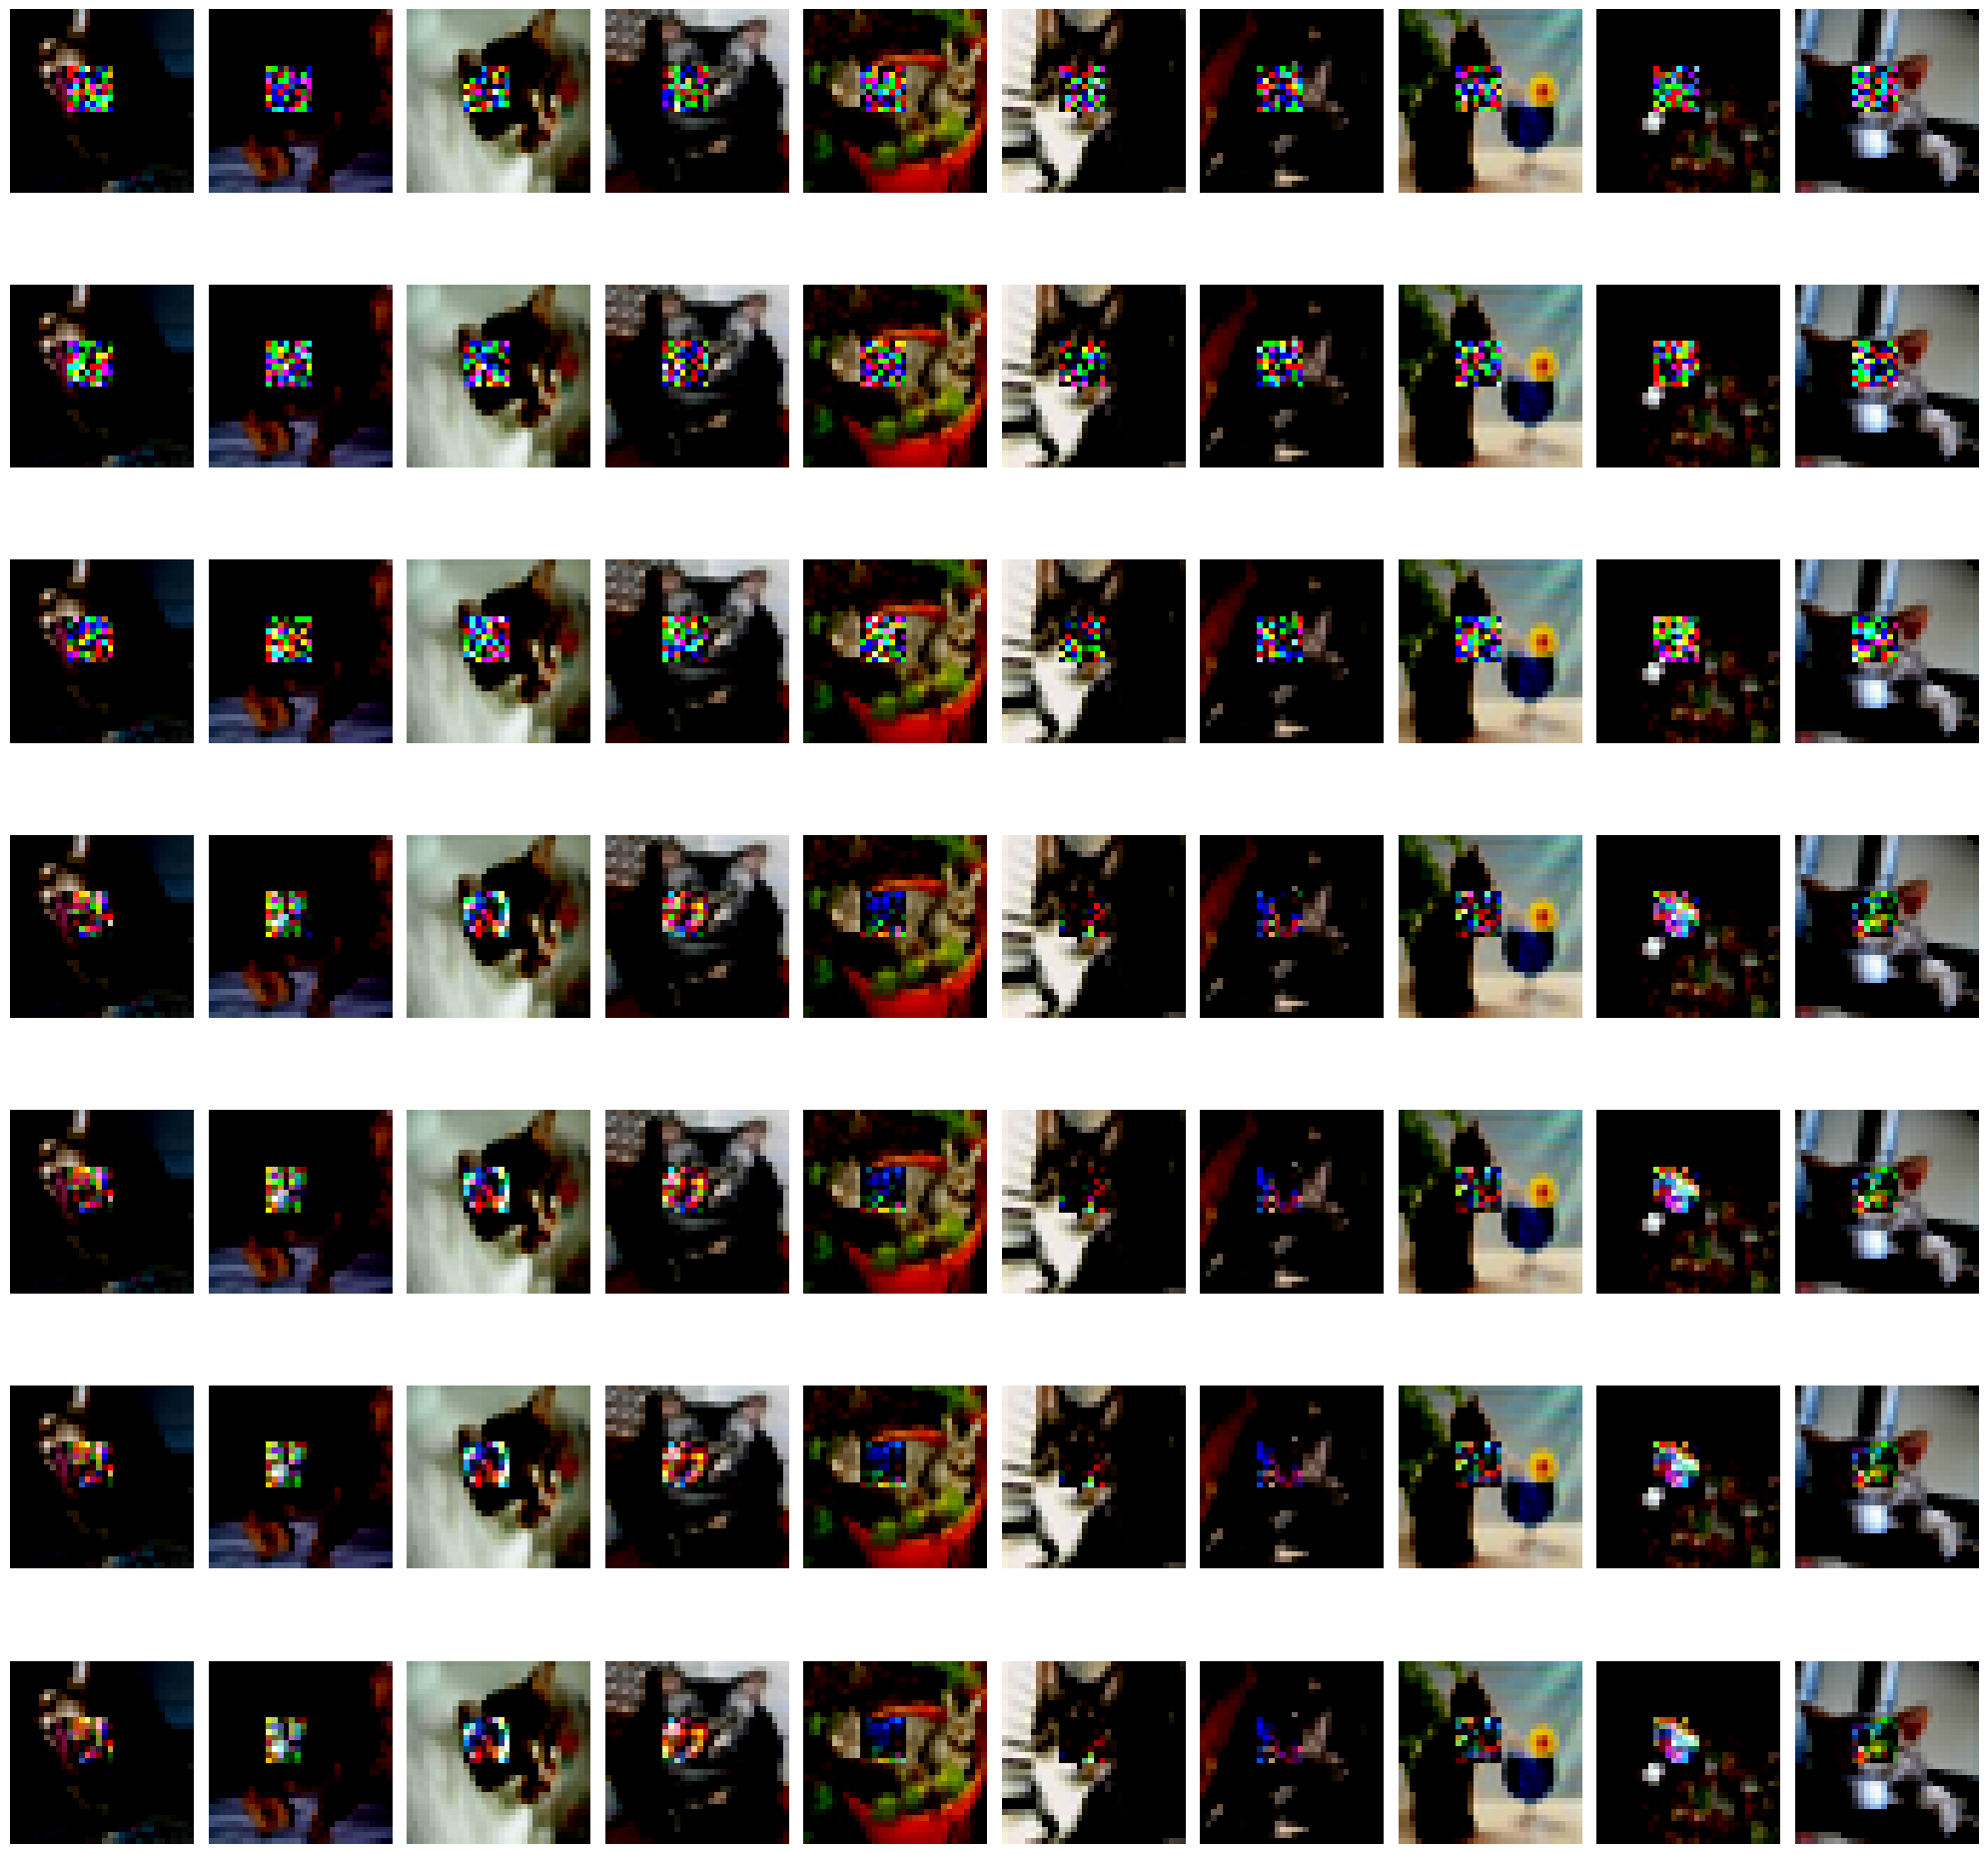

In [ ]:
generate_and_plot(model_cifar, dataset=dataset, diffusion_type=diffusion_type, schedule_type=schedule_type, sampler=sampler, label=label, imputation=imputation)
# En CIFAR-10, ta etiqueta 3 se refiere a "cat"(gato)

## Cambio de sampler
Cambiamos el sampler de Euler-Maruyama, para probar cómo se imprimen las imágenes con el resto de samplers. En este caso no hace falta reentrenar el modelo, ya que el sampler solo afecta a la función generate_and_plot.

Files already downloaded and verified


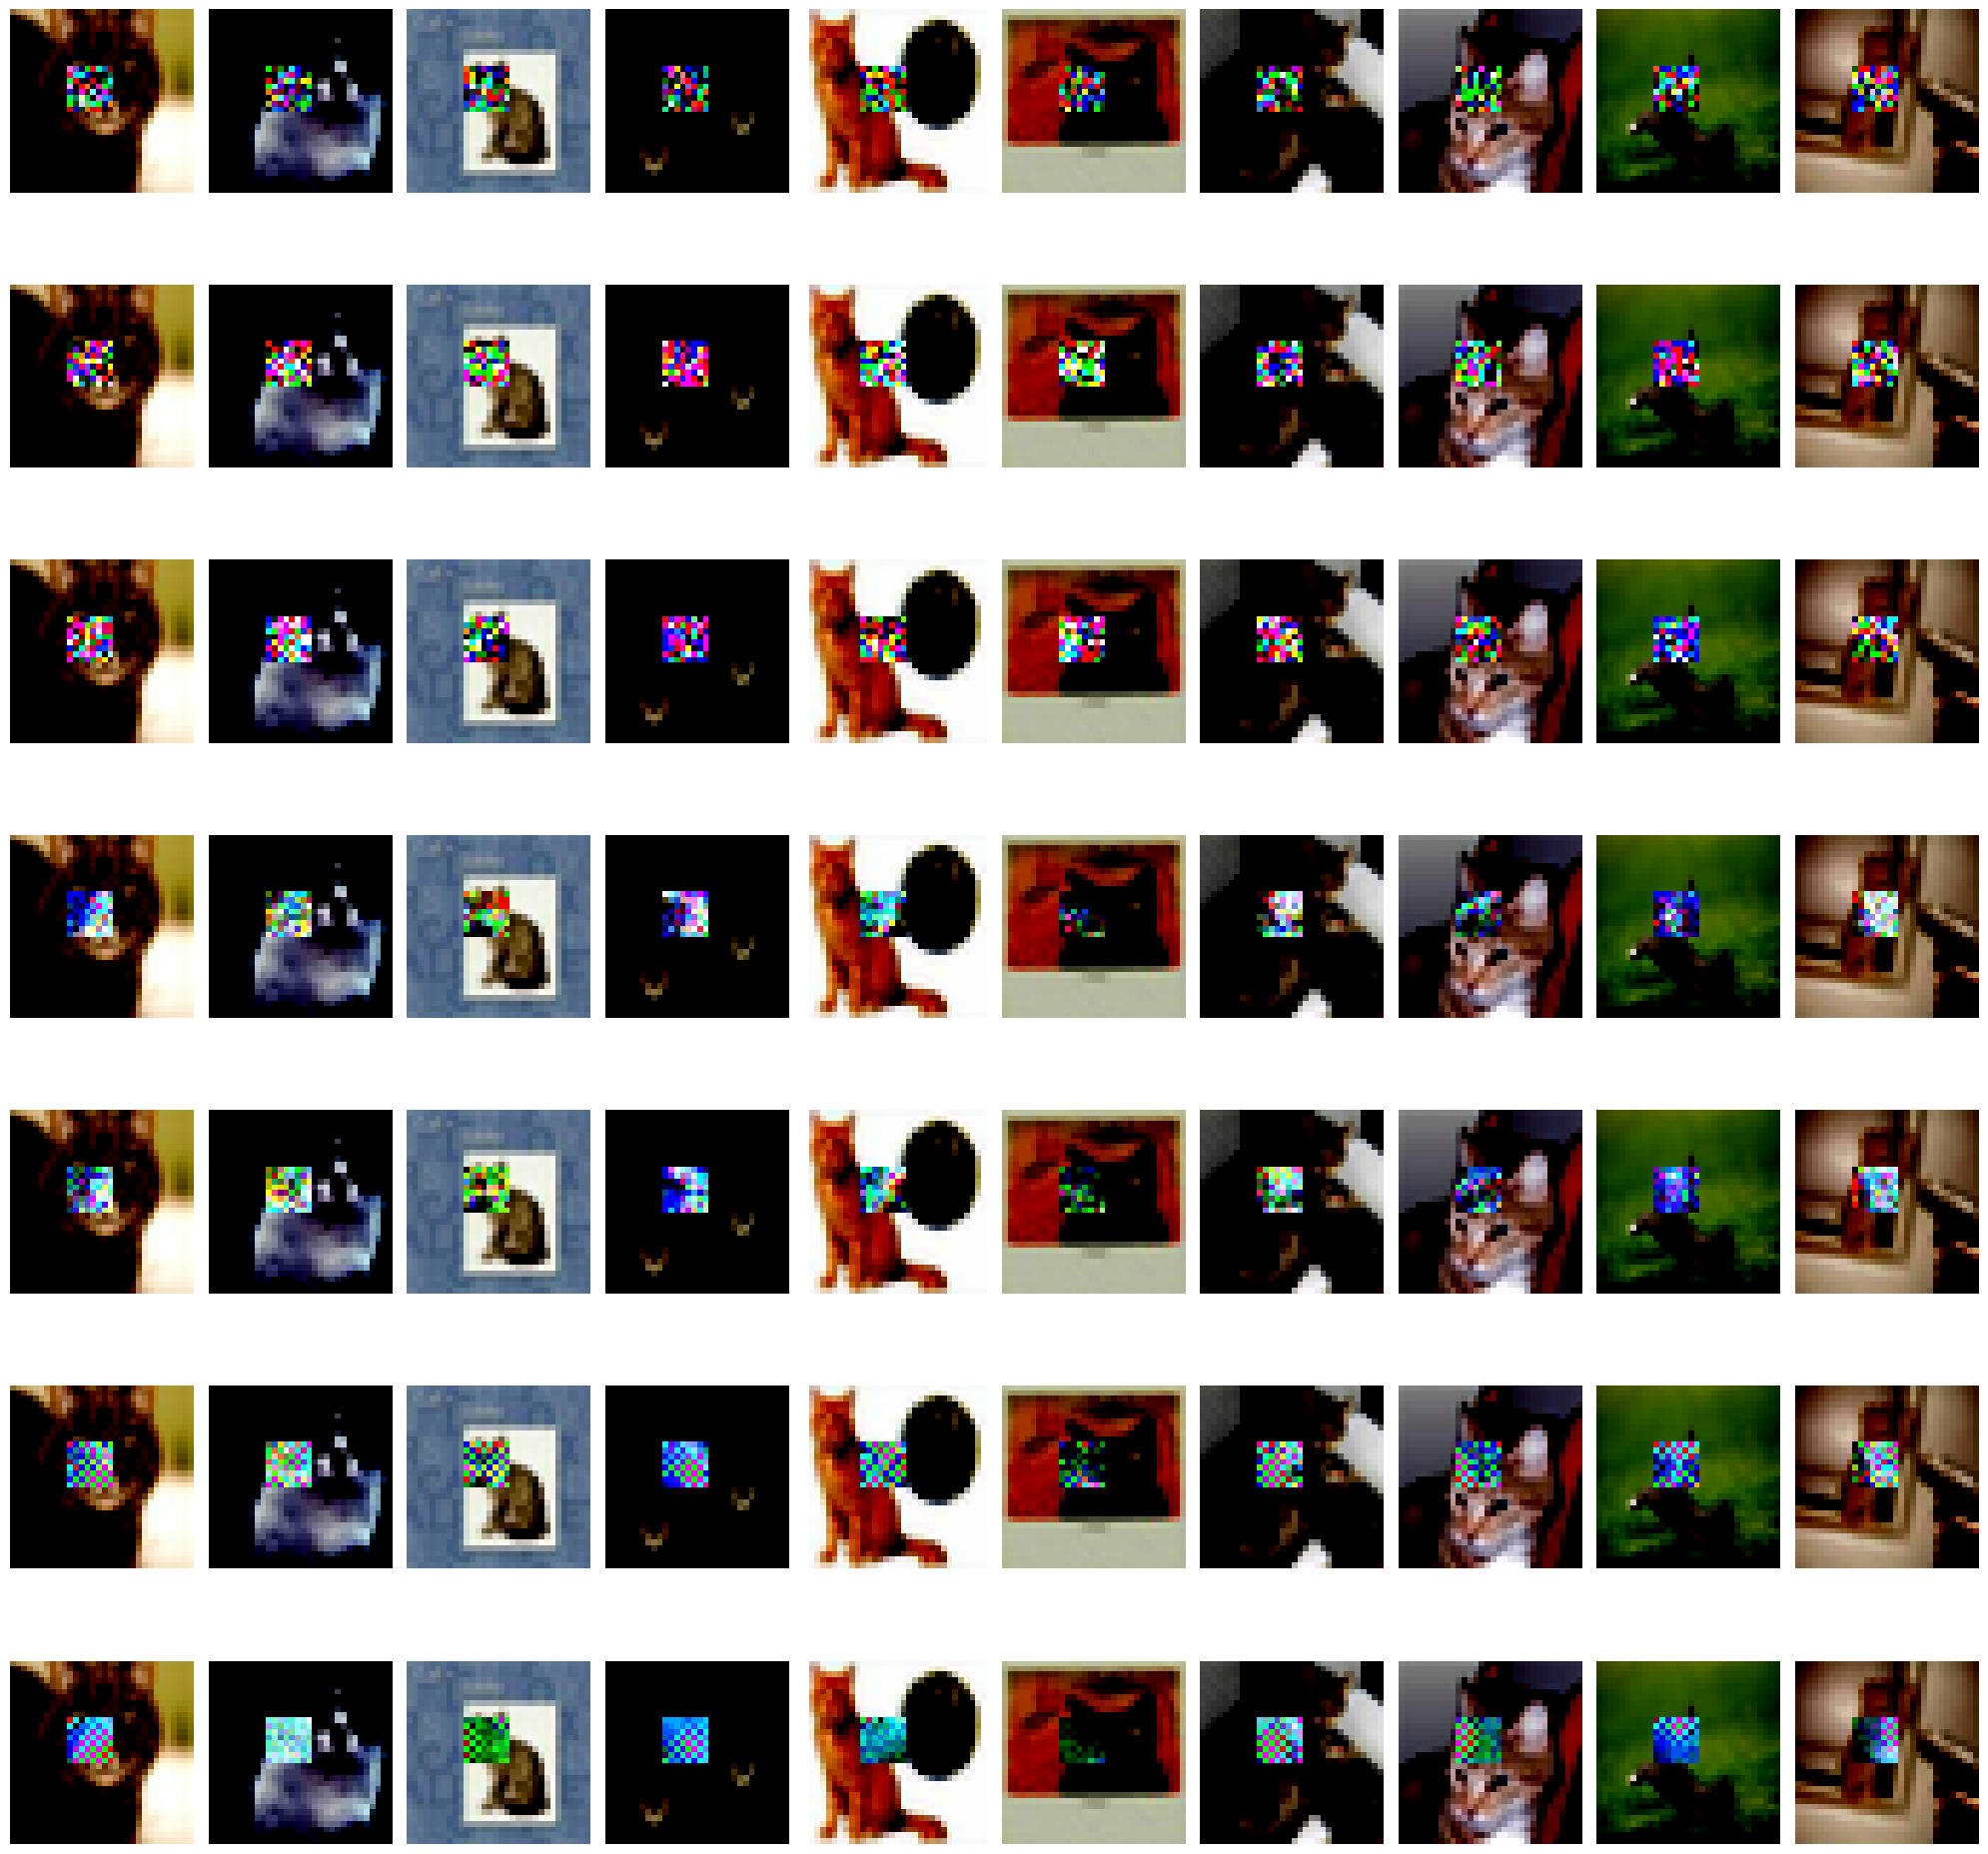

In [11]:
# Sampler: Predictor-Corrector
generate_and_plot(model_cifar, dataset=dataset, diffusion_type=diffusion_type, schedule_type=schedule_type, sampler="pc", label=label, imputation=imputation)

Files already downloaded and verified


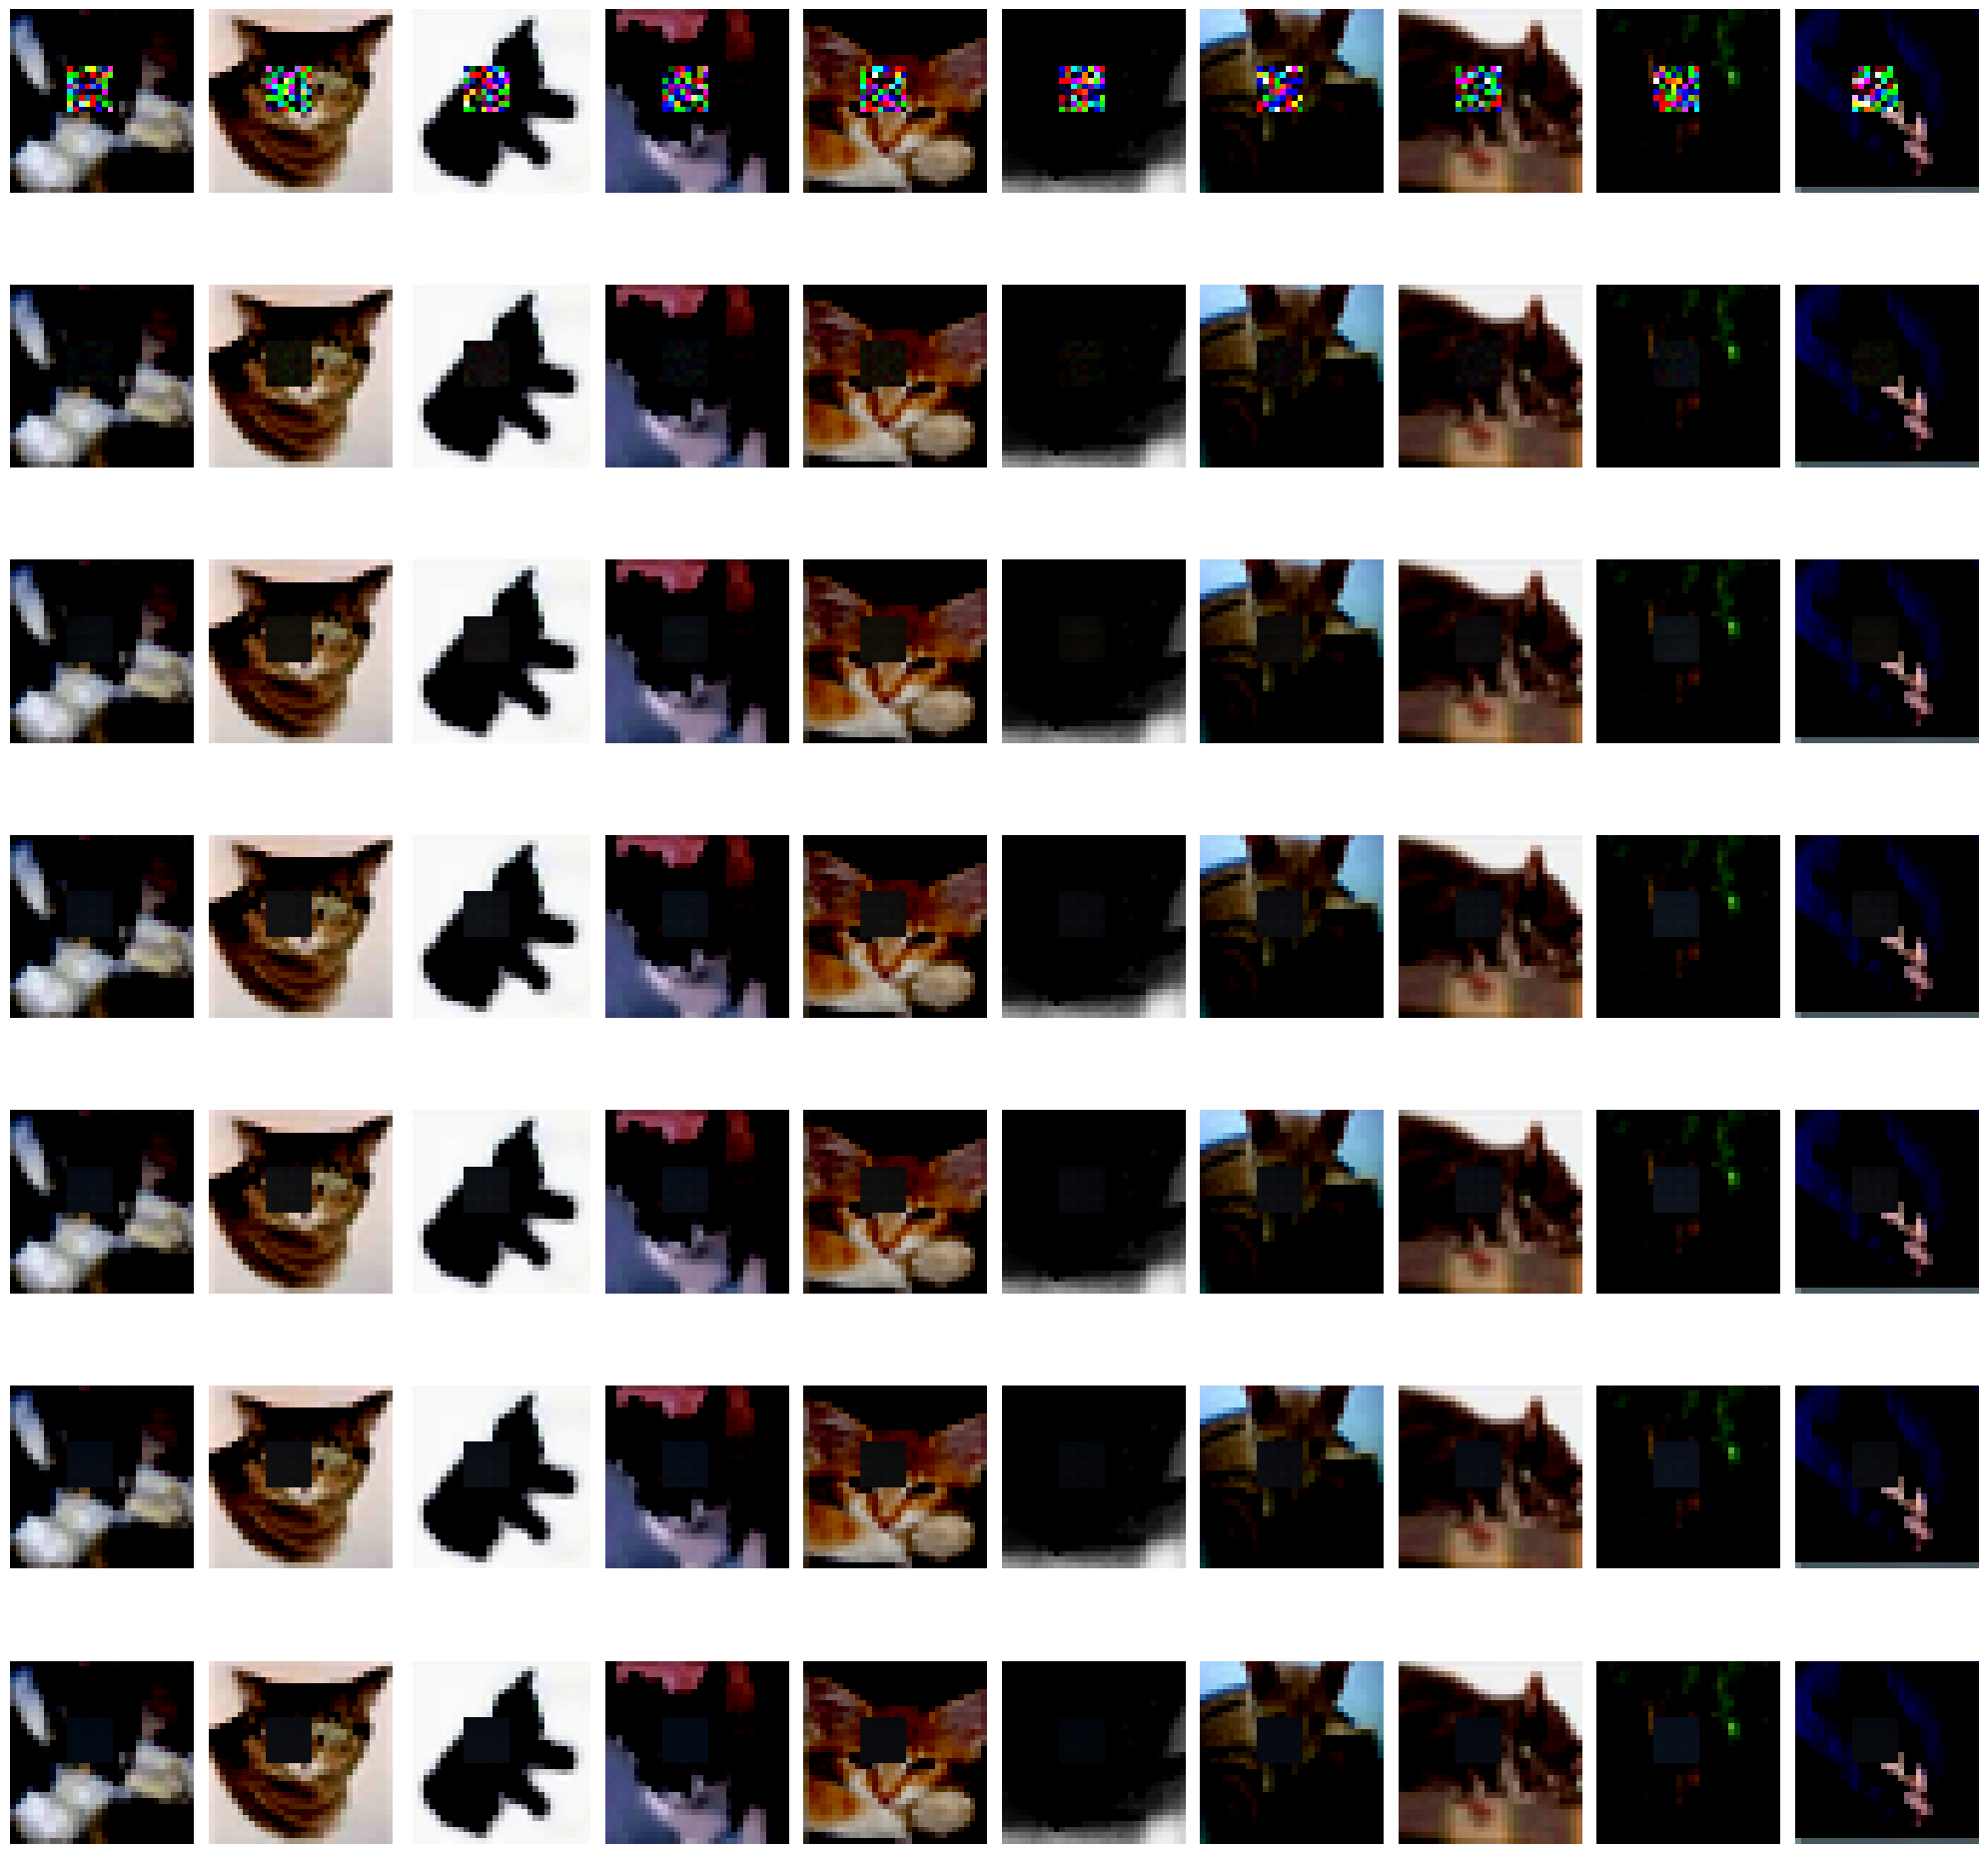

In [12]:
# Sampler: Probability Flow ODE
generate_and_plot(model_cifar, dataset=dataset, diffusion_type=diffusion_type, schedule_type=schedule_type, sampler="pf", label=label, imputation=imputation)

Files already downloaded and verified


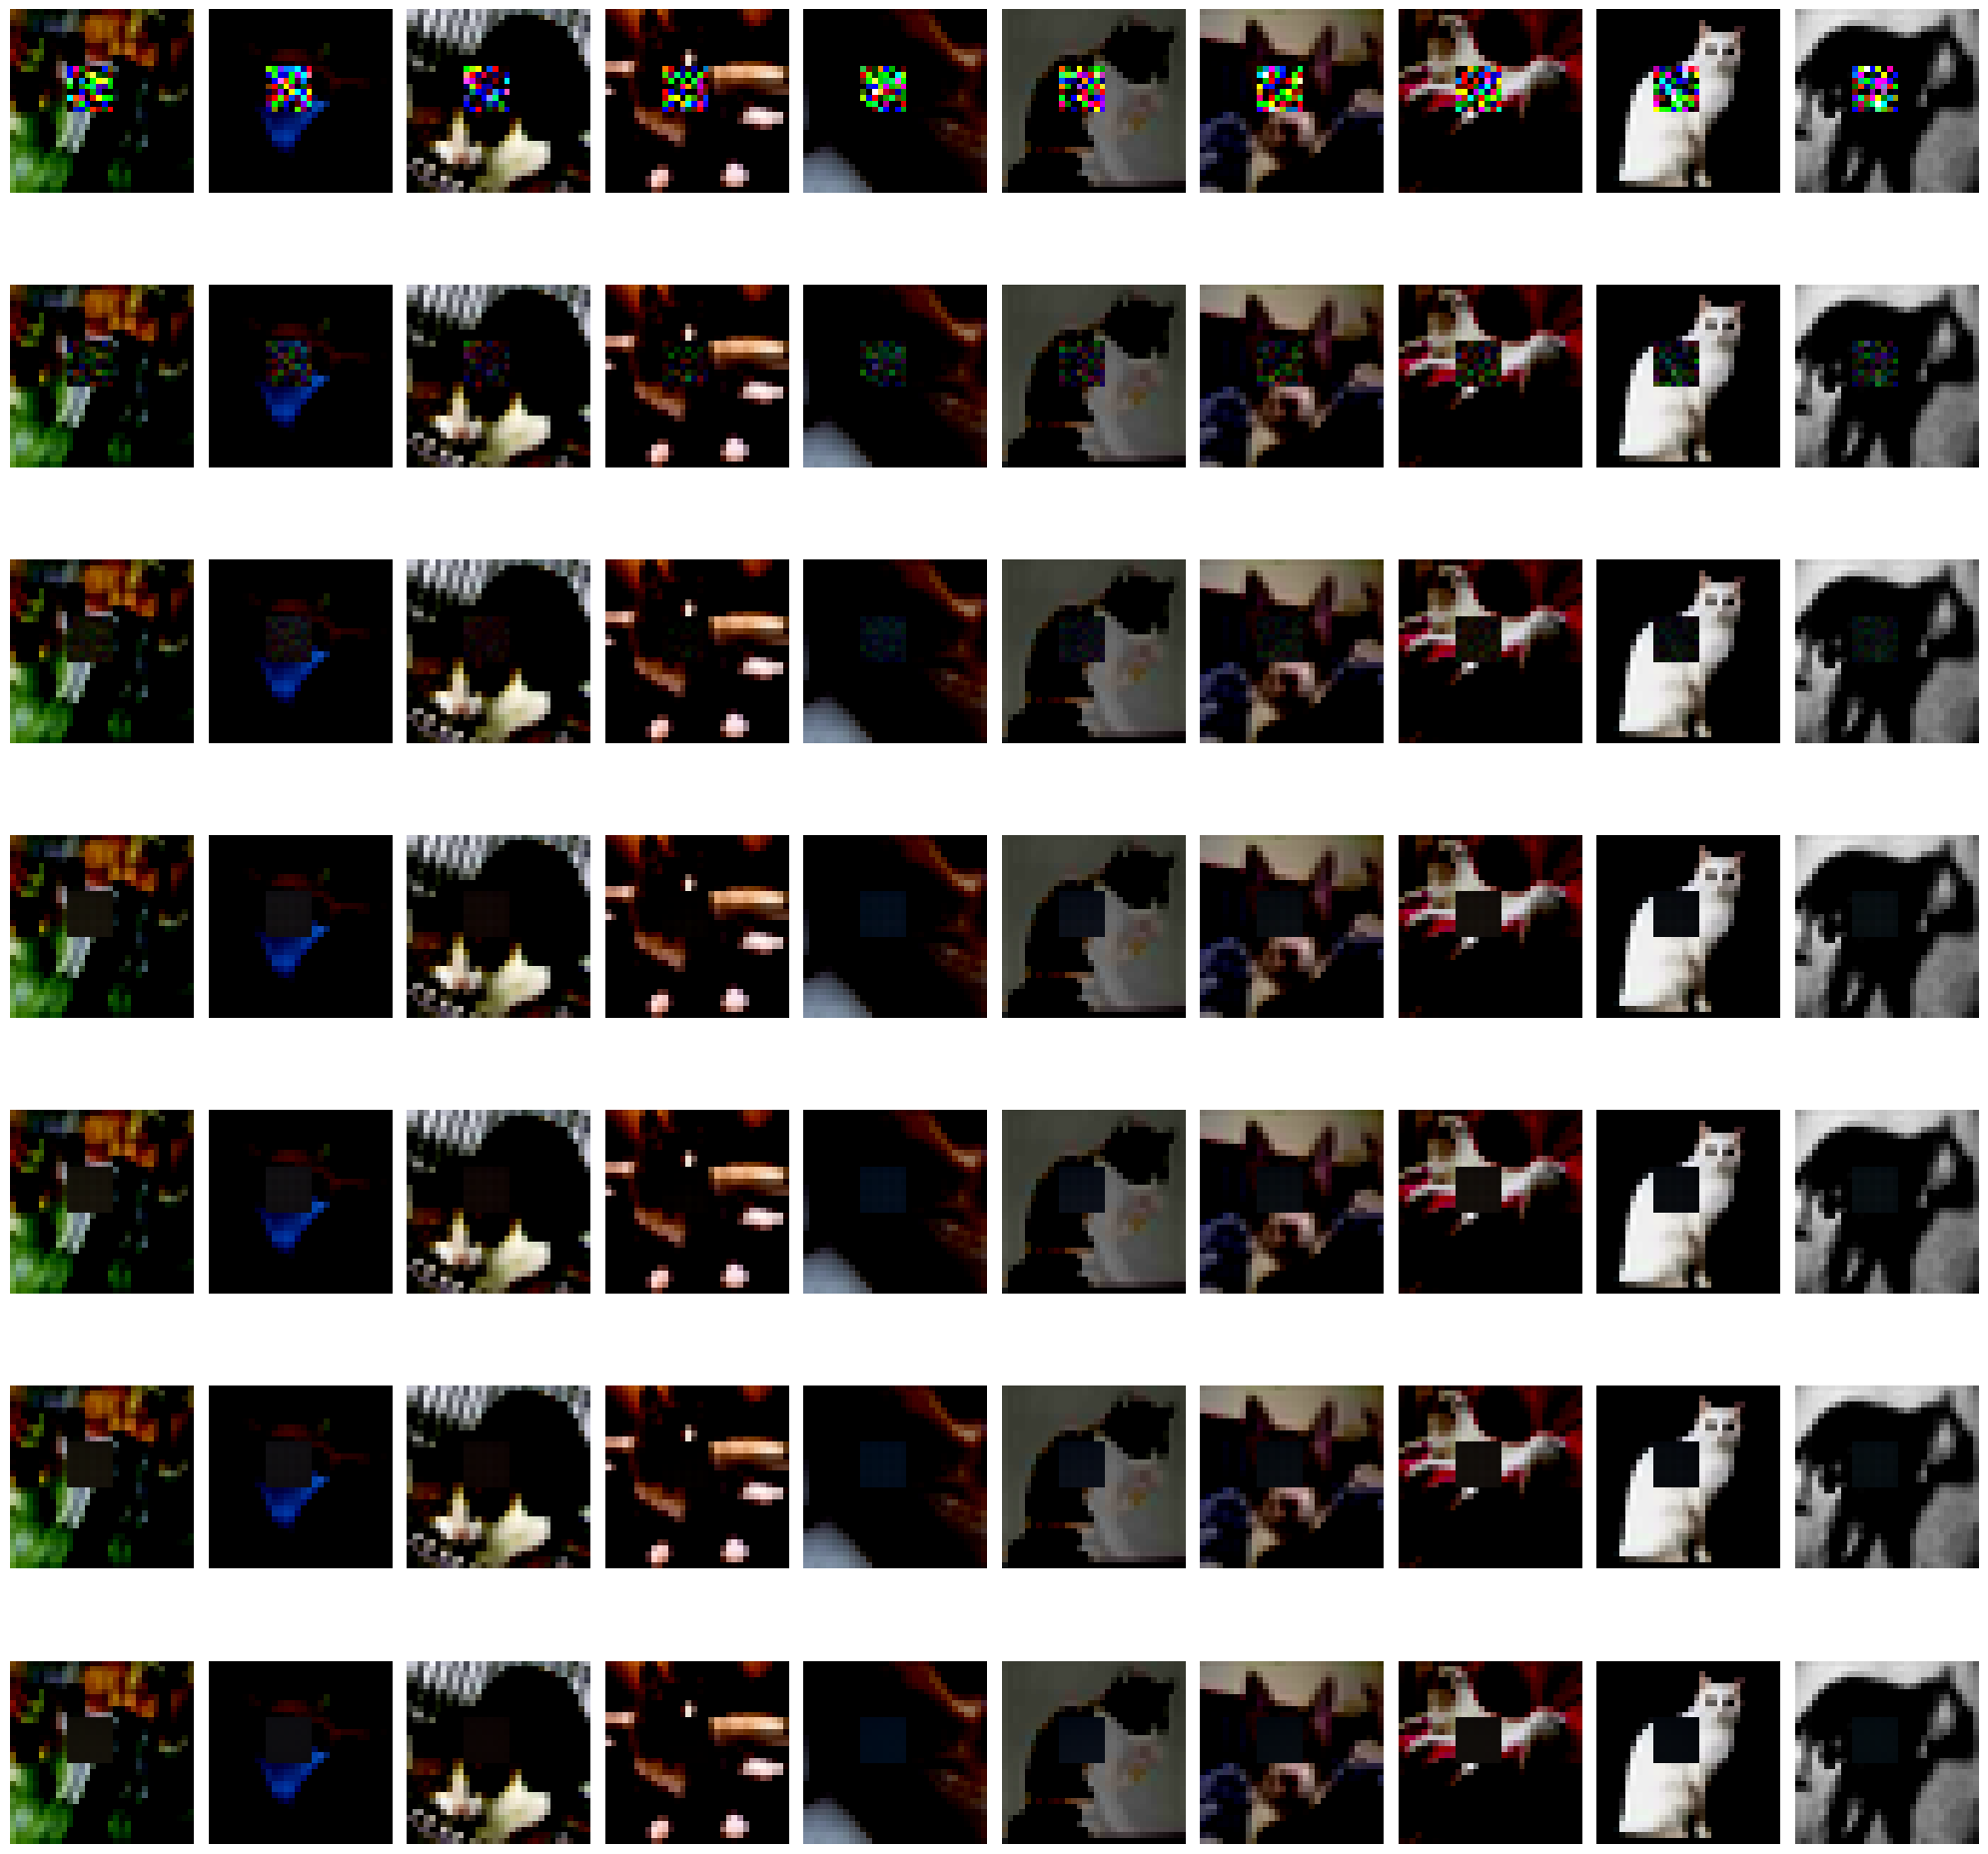

In [13]:
# Sampler: Exponential Integrator
generate_and_plot(model_cifar, dataset=dataset, diffusion_type=diffusion_type, schedule_type=schedule_type, sampler="expint", label=label, imputation=imputation)